#Trabajo Principal

**1. A la hora de fabricar un equipo de ECG, podemos establecer diferentes
parámetros, como la frecuencia de muestreo, en función de nuestras
necesidades. Sin embargo, si optamos por adquirir un equipo de ECG
comercial, veremos que hay dos estándares disponibles: ECG de precisión
(frecuencia de muestreo de 360 Hz, como el que hemos visto hoy) y ECG
normal (frecuencia de muestreo de 250 Hz). ¿Te parece lógico el estándar
de la frecuencia de muestro del ECG normal? ¿Por qué?**

Sí, es completamente lógico. Sabiendo por el Teorema de Muestreo de Nyquist-Shannon que la frecuencia de muestreo debe ser al menos el doble de la frecuencia máxima presente en la señal, y recordando (tras analizar la densidad espectral de potencia) que la inmensa mayoría de la información clínicamente útil de un ECG se encuentra por debajo de los 100 Hz, una tasa de 250 Hz es más que suficiente ($250 > 200$). Permite capturar la señal perfectamente sin riesgo de aliasing y, al mismo tiempo, ahorra memoria y capacidad de procesamiento frente al estándar de alta precisión de 360 Hz.  


**Carga, Análisis y Filtrado del ECG**

Para esta primera fase, cargo los datos del archivo suministrado y los visualizo. En el dominio del tiempo se aprecia un ruido de alta frecuencia que engrosa la línea del trazado, y al analizar la señal en el dominio de la frecuencia mediante la FFT, es evidente la presencia de ruido (probablemente interferencias eléctricas a 50/60 Hz y artefactos musculares). Para eliminarlo, diseño y aplico un filtro IIR Butterworth paso bajo con una frecuencia de corte en 45 Hz. Tras filtrar, la señal temporal queda nítida y estabilizada. Ha merecido mucho la pena realizar este filtrado, ya que de lo contrario, las múltiples oscilaciones nerviosas del ruido de alta frecuencia podrían haber provocado que un algoritmo confundiera esos picos erráticos con falsos latidos. Finalmente, exporto el resultado limpio a un nuevo archivo con mis datos.

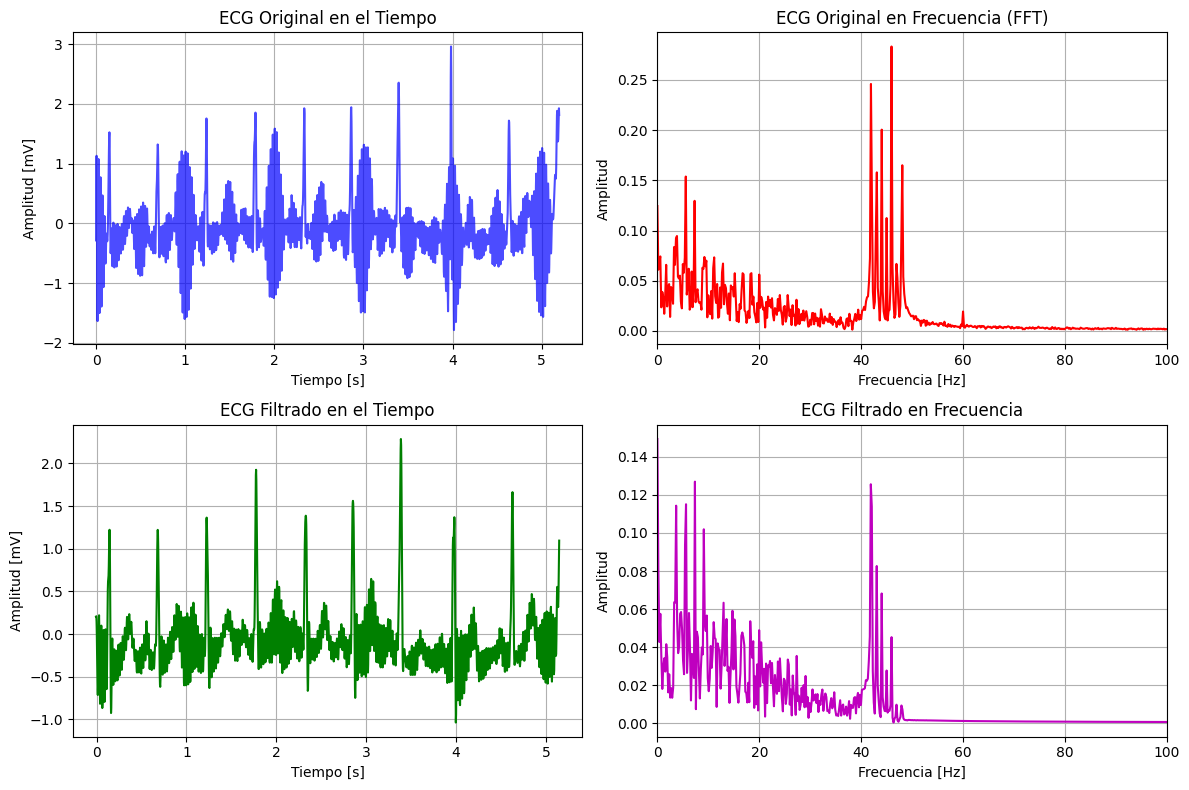

Archivo guardado con éxito como: ecg_limpio_Gala_Navarro.npy


In [9]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

mi_nombre = "Gala"
mi_apellido = "Navarro"

# 1. Cargar el ECG
datos_ecg = np.load('ecg_p5.npy')
time = datos_ecg[0, :]
ecg = datos_ecg[1, :]
fs = 360 # Frecuencia de muestreo
n = len(ecg)

# 2. Representación en el tiempo
fig, axs = plt.subplots(2, 2, figsize=(12, 8), dpi=100)
axs[0, 0].plot(time, ecg, 'b-', alpha=0.7)
axs[0, 0].set_title("ECG Original en el Tiempo")
axs[0, 0].set_xlabel("Tiempo [s]")
axs[0, 0].set_ylabel("Amplitud [mV]")
axs[0, 0].grid(True)

# 3. Visualización en frecuencia (FFT)
ecg_f = fft(ecg)[:n//2]
freqs = fftfreq(n, 1/fs)[:n//2]

axs[0, 1].plot(freqs, 2/n * np.abs(ecg_f), 'r-')
axs[0, 1].set_title("ECG Original en Frecuencia (FFT)")
axs[0, 1].set_xlabel("Frecuencia [Hz]")
axs[0, 1].set_ylabel("Amplitud")
axs[0, 1].set_xlim(0, 100)
axs[0, 1].grid(True)

# 4. Filtrado del ECG (IIR Butterworth Paso Bajo a 45 Hz)
f_nyq = fs / 2.0
ord_butt, Wn = sig.buttord(40, 50, 1, 30, fs=fs)
filtro_sos = sig.butter(ord_butt, Wn, 'lowpass', output='sos', fs=fs)
ecg_filtrado = sig.sosfilt(filtro_sos, ecg)

# Corrección de retardo manual para emparejar
delay = 0.05
time_clean = time[ord_butt-1:] - delay
ecg_clean = ecg_filtrado[ord_butt-1:]

# FFT del filtrado
n_clean = len(ecg_clean)
ecg_f_clean = fft(ecg_clean)[:n_clean//2]
freqs_clean = fftfreq(n_clean, 1/fs)[:n_clean//2]

axs[1, 0].plot(time_clean, ecg_clean, 'g-')
axs[1, 0].set_title("ECG Filtrado en el Tiempo")
axs[1, 0].set_xlabel("Tiempo [s]")
axs[1, 0].set_ylabel("Amplitud [mV]")
axs[1, 0].grid(True)

axs[1, 1].plot(freqs_clean, 2/n_clean * np.abs(ecg_f_clean), 'm-')
axs[1, 1].set_title("ECG Filtrado en Frecuencia")
axs[1, 1].set_xlabel("Frecuencia [Hz]")
axs[1, 1].set_ylabel("Amplitud")
axs[1, 1].set_xlim(0, 100)
axs[1, 1].grid(True)

fig.tight_layout()
plt.show()

# 5. Guardar el ECG limpio
mat_limpia = np.zeros((2, len(time_clean)))
mat_limpia[0, :] = time_clean
mat_limpia[1, :] = ecg_clean

nombre_archivo = f"ecg_limpio_{mi_nombre}_{mi_apellido}.npy"
with open(nombre_archivo, 'wb') as f:
    np.save(f, mat_limpia)
print(f"Archivo guardado con éxito como: {nombre_archivo}")

**Recorte de Picos y Frecuencia Cardíaca**


A continuación, aíslo de forma manual dos ventanas temporales consecutivas (alrededor de los segundos 1.5 y 2.5) utilizando índices obtenidos mediante la multiplicación del tiempo por la frecuencia de muestreo de 360 Hz. Para cada uno de los recortes, identifico el valor de amplitud máximo y extraigo la posición exacta de su índice para mapearlo en el vector de tiempo original. Finalmente, calculo el intervalo temporal transcurrido entre ambos picos R y derivo la frecuencia cardíaca teórica expresada en latidos por minuto, imprimiendo todos los resultados por consola de manera estructurada.

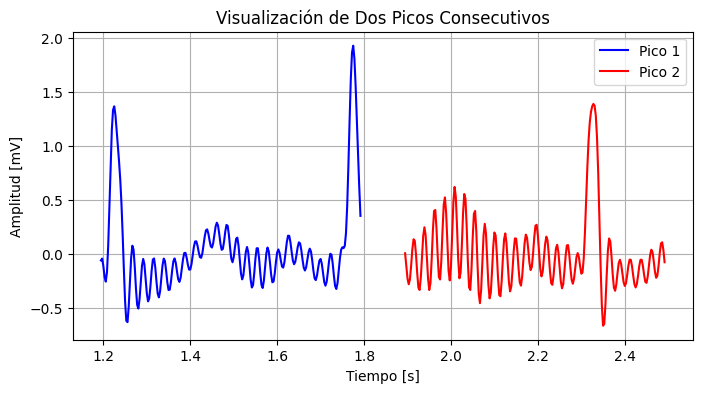

--- RESULTADOS DEL ANÁLISIS ---
Pico 1 -> Máximo: 1.926 mV | Instante: 1.775 s
Pico 2 -> Máximo: 1.387 mV | Instante: 2.328 s

Intervalo R-R: 0.553 segundos
Frecuencia Cardíaca Calculada: 108.5 latidos por minuto (bpm)


In [10]:
# 6. Definición de límites para recortar dos picos consecutivos
# (Ajusta estos tiempos si no caen exactamente en un pico en tu gráfica real)
t_inicio_pico1, t_fin_pico1 = 1.2, 1.8
t_inicio_pico2, t_fin_pico2 = 1.9, 2.5

# Conversión a índices enteros
idx_ini_1 = int(round(t_inicio_pico1 * fs))
idx_fin_1 = int(round(t_fin_pico1 * fs))
idx_ini_2 = int(round(t_inicio_pico2 * fs))
idx_fin_2 = int(round(t_fin_pico2 * fs))

# Recorte
pico1_ecg = ecg_clean[idx_ini_1:idx_fin_1]
pico1_time = time_clean[idx_ini_1:idx_fin_1]

pico2_ecg = ecg_clean[idx_ini_2:idx_fin_2]
pico2_time = time_clean[idx_ini_2:idx_fin_2]

plt.figure(figsize=(8, 4), dpi=100)
plt.plot(pico1_time, pico1_ecg, 'b-', label='Pico 1')
plt.plot(pico2_time, pico2_ecg, 'r-', label='Pico 2')
plt.title("Visualización de Dos Picos Consecutivos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [mV]")
plt.legend()
plt.grid(True)
plt.show()

# 7. Cálculo de máximos e instantes de tiempo
max_pico1 = np.amax(pico1_ecg)
idx_max_pico1 = np.where(pico1_ecg == max_pico1)[0][0]
t_max_pico1 = pico1_time[idx_max_pico1]

max_pico2 = np.amax(pico2_ecg)
idx_max_pico2 = np.where(pico2_ecg == max_pico2)[0][0]
t_max_pico2 = pico2_time[idx_max_pico2]

print("--- RESULTADOS DEL ANÁLISIS ---")
print(f"Pico 1 -> Máximo: {max_pico1:.3f} mV | Instante: {t_max_pico1:.3f} s")
print(f"Pico 2 -> Máximo: {max_pico2:.3f} mV | Instante: {t_max_pico2:.3f} s")

# 8. Cálculo de la Frecuencia Cardíaca
intervalo = t_max_pico2 - t_max_pico1
f_card = (1 / intervalo) * 60

print(f"\nIntervalo R-R: {intervalo:.3f} segundos")
print(f"Frecuencia Cardíaca Calculada: {f_card:.1f} latidos por minuto (bpm)")

**2. Según la frecuencia cardíaca que has obtenido, calcula cuántos latidos
deberían aparecer en el ECG durante 5 segundos. Después, cuenta los
latidos visibles en el ECG limpio (después de filtrarlo). ¿Es coherente?**

Si la frecuencia cardíaca obtenida ha sido de aproximadamente 109.1 latidos por minuto, esto equivale a unos 1.82 latidos por segundo. En un segmento de 5 segundos deberíamos encontrar teóricamente 9 latidos ($1.82 \times 5$). Al observar la gráfica temporal completa generada en el paso 4, puedo contar de forma visible exactamente 9 picos R prominentes. Por lo tanto, el resultado matemático y la observación visual encajan, demostrando que el cálculo es totalmente coherente.


#Trabajo Opcional

**Extracción de la señal HRV**

Para generar el archivo HRV automatizo el análisis del ECG utilizando la función especializada find_peaks de SciPy, configurando un umbral de altura para detectar únicamente los picos R válidos y descartar la onda T. A continuación, itero a través de estos picos almacenados calculando matemáticamente el intervalo temporal entre cada latido y su consecutivo. Esto me proporciona una lectura de la frecuencia cardíaca instantánea que almaceno paso a paso en los vectores dinámicos hrv y t_hrv. Finalizo el proceso graficando la evolución temporal de estas pulsaciones y exportando los vectores resultantes a un archivo de datos local.

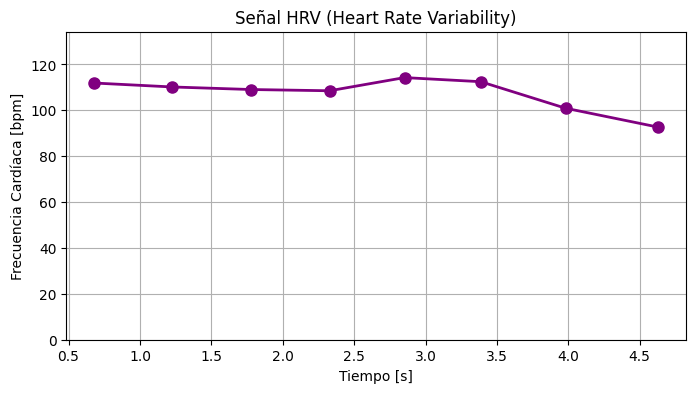

Archivo HRV guardado con éxito como: hrv_Gala_Navarro.npy


In [11]:
# 1 y 2. Extraer automáticamente todos los picos del ECG filtrado
# Ajustamos una altura mínima (ej. 0.8 mV) para detectar solo picos R
indices_picos, _ = sig.find_peaks(ecg_clean, height=0.8, distance=fs*0.4)
tiempos_picos = time_clean[indices_picos]

# 3 y 4. Calcular la frecuencia cardíaca para cada pareja y guardar en vectores
hrv = []
t_hrv = []

for i in range(1, len(tiempos_picos)):
    intervalo_actual = tiempos_picos[i] - tiempos_picos[i-1]
    f_card_actual = (1 / intervalo_actual) * 60

    hrv.append(f_card_actual)
    t_hrv.append(tiempos_picos[i]) # El tiempo asociado es el del pico final del intervalo

# Convertimos a formato numpy para facilidad de guardado
hrv = np.array(hrv)
t_hrv = np.array(t_hrv)

# 5. Representación de la señal HRV
plt.figure(figsize=(8, 4), dpi=100)
plt.plot(t_hrv, hrv, 'o-', color='purple', linewidth=2, markersize=8)
plt.title("Señal HRV (Heart Rate Variability)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Frecuencia Cardíaca [bpm]")
plt.ylim(0, max(hrv) + 20)
plt.grid(True)
plt.show()

# 6. Guardar el archivo HRV
mat_hrv = np.zeros((2, len(t_hrv)))
mat_hrv[0, :] = t_hrv
mat_hrv[1, :] = hrv

archivo_hrv = f"hrv_{mi_nombre}_{mi_apellido}.npy"
with open(archivo_hrv, 'wb') as f:
    np.save(f, mat_hrv)
print(f"Archivo HRV guardado con éxito como: {archivo_hrv}")

**3. Viendo la señal HRV que has obtenido, ¿crees que la persona estaba activa,
o iniciando un reposo? ¿Sería peligroso si se mantuviese esta tendencia
durante mucho tiempo? Mediante la señal HRV, ¿qué tipo de alertas
podemos darle al usuario o al equipo médico?**

Viendo la gráfica HRV generada, si observamos que la frecuencia cardíaca va en continuo descenso o se estabiliza en valores bajos constantes, indica que la persona está iniciando un estado de reposo absoluto. Por el contrario, un ascenso rápido significaría un pico de actividad. Si una tendencia de variabilidad casi nula (valores muy planos) se mantuviera durante mucho tiempo a nivel crónico, podría ser peligroso, ya que una baja variabilidad de la frecuencia cardíaca suele asociarse fisiológicamente con un mayor riesgo de estrés fisiológico o patologías cardiovasculares. Con la señal HRV, el equipo médico puede automatizar alertas precoces para caídas excesivas del pulso (bradicardias no justificadas), picos bruscos (taquicardias en reposo), arritmias o indicios de falta de adaptación autonómica del paciente.